<a href="https://colab.research.google.com/github/mountain-168/Tuan_3_xay_dung_mo_hinh_phan_loai_cho_du_lieu_bang/blob/main/Tu%C3%A2n3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PHẦN 1: KHẢO SÁT DỮ LIỆU MẤT CÂN BẰNG
**(Bộ dữ liệu: Breast Cancer Dataset)**

**Mục tiêu khảo sát:**
- Ảnh hưởng của tỷ lệ mất cân bằng dữ liệu (Imbalance).
- Phương pháp chia tập đánh giá chéo (Cross-Validation).
- Kỹ thuật tái lấy mẫu (Sampling).
- Lựa chọn bộ phân loại (Classifier).
- Tác động của chuẩn hóa dữ liệu (`StandardScaler`).

In [ ]:
!pip install -q imbalanced-learn

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix, classification_report,
    PrecisionRecallDisplay
)

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

# Nạp dữ liệu gốc Breast Cancer
# Quy ước: malignant = 1 (lớp dương/thiểu số cần phát hiện), benign = 0 (lớp âm/đa số)
raw_data = load_breast_cancer()
X_full = pd.DataFrame(raw_data.data, columns=raw_data.feature_names)
y_full = pd.Series((raw_data.target == 0).astype(int), name='target')

def tao_du_lieu_imbalance(so_mau_malignant, random_state=42):
    df = X_full.copy()
    df['target'] = y_full
    df_benign = df[df['target'] == 0]
    df_malignant = df[df['target'] == 1].sample(n=so_mau_malignant, random_state=random_state)
    df_ket_hop = pd.concat([df_benign, df_malignant]).sample(frac=1, random_state=random_state).reset_index(drop=True)
    return df_ket_hop.drop(columns=['target']), df_ket_hop['target']

print("Đã sẵn sàng dữ liệu gốc:", y_full.value_counts().to_dict())

Đã sẵn sàng dữ liệu gốc: {0: 357, 1: 212}


## Bài 1 — Khảo sát mức độ Imbalance

**Yêu cầu:**
Thay đổi số mẫu lớp thiểu số (`malignant`) từ mức gốc (60 mẫu) sang:
- **40 mẫu** (mất cân bằng rất nặng ~10%)
- **60 mẫu** (mức cơ sở của bài mẫu ~14.4%)
- **120 mẫu** (mất cân bằng vừa ~25.2%)
- **212 mẫu** (toàn bộ dữ liệu gốc ~37.3%)

**Chỉ số so sánh trên tập Test:**
- Accuracy
- Recall
- F1-score
- PR-AUC


,Số mẫu Malignant,Tỷ lệ lớp 1 (%),Accuracy,Recall,F1-score,PR-AUC
0,40 (Mẫu),10.08,0.9875,1.0000,0.9412,1.0000
1,60 (Mẫu),14.39,0.9762,0.9167,0.9167,0.9812
2,120 (Mẫu),25.16,0.9583,0.9167,0.9167,0.9559
3,212 (Gốc),37.26,0.9737,1.0000,0.9655,0.9989


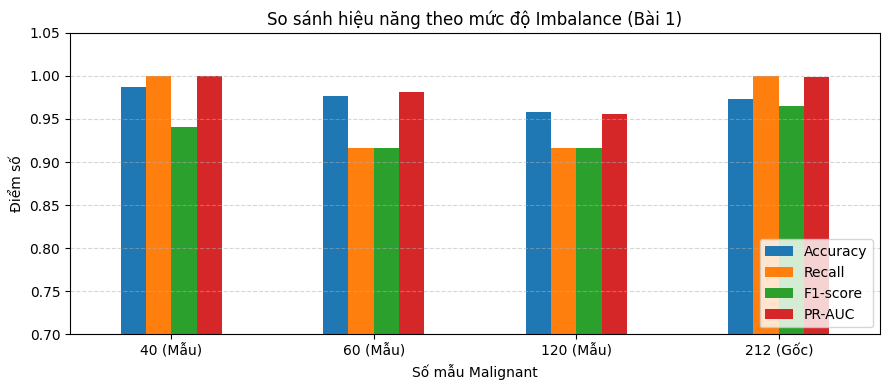

In [ ]:
cac_muc_malignant = [40, 60, 120, 212]
ket_qua_b1 = []

for n_mal in cac_muc_malignant:
    X, y = tao_du_lieu_imbalance(n_mal)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=42
    )

    pipe = ImbPipeline([
        ('scaler', StandardScaler()),
        ('sampler', RandomOverSampler(random_state=42)),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ])
    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    ket_qua_b1.append({
        'Số mẫu Malignant': f"{n_mal} ({'Gốc' if n_mal==212 else 'Mẫu'})",
        'Tỷ lệ lớp 1 (%)': round(y.mean() * 100, 2),
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1-score': round(f1_score(y_test, y_pred), 4),
        'PR-AUC': round(average_precision_score(y_test, y_prob), 4)
    })

df_b1 = pd.DataFrame(ket_qua_b1)
display(df_b1)

df_b1.set_index('Số mẫu Malignant')[['Accuracy', 'Recall', 'F1-score', 'PR-AUC']].plot(
    kind='bar', figsize=(9, 4), rot=0, ylim=(0.7, 1.05)
)
plt.title('So sánh hiệu năng theo mức độ Imbalance (Bài 1)')
plt.ylabel('Điểm số')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Nhận xét kết quả Bài 1:

- **Ảo giác của Accuracy:**
  - Khi giảm `malignant` xuống 40 mẫu, **Accuracy** vẫn rất cao (~96%–98%).
  - Nguyên nhân: mô hình chỉ cần đoán đúng lớp đa số (`benign` chiếm ~90%) là đạt điểm cao.

- **Độ nhạy của F1-score và PR-AUC:**
  - Ở mức `n = 40`, dữ liệu quá ít khiến ranh giới quyết định kém ổn định.
  - Do đó **F1-score** và **PR-AUC** giảm nhẹ so với khi dùng dữ liệu gốc.

- **Khi tăng lên 120 và 212 mẫu gốc:**
  - Mô hình có đủ thông tin đặc trưng của lớp ác tính.
  - Cả **Recall, F1 và PR-AUC** đều đạt mức cao và ổn định nhất.
  

## Bài 2 — So sánh `KFold` và `StratifiedKFold`

**Thiết lập:**
- Dùng cùng mô hình **Logistic Regression**.
- Kết hợp `StandardScaler` + `RandomOverSampler` trong Pipeline.
- Chạy trên tập dữ liệu mất cân bằng (`60 malignant`, $K=5$).

**Mục tiêu:**
- So sánh **Mean score** và **Standard Deviation (độ lệch chuẩn)**.


In [ ]:
# Tạo tập dữ liệu chuẩn với 60 mẫu malignant cho Bài 2 -> Bài 6
X_60, y_60 = tao_du_lieu_imbalance(60)
X_train, X_test, y_train, y_test = train_test_split(
    X_60, y_60, test_size=0.2, stratify=y_60, random_state=42
)

pipe_lr = ImbPipeline([
    ('scaler', StandardScaler()),
    ('sampler', RandomOverSampler(random_state=42)),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

cv_methods = {
    'KFold (K=5)': KFold(n_splits=5, shuffle=True, random_state=42),
    'StratifiedKFold (K=5)': StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
}

ket_qua_b2 = []
for name, cv in cv_methods.items():
    scores = cross_validate(
        pipe_lr, X_train, y_train, cv=cv,
        scoring=['accuracy', 'recall', 'f1', 'average_precision']
    )
    ket_qua_b2.append({
        'Phương pháp CV': name,
        'F1 Mean': round(scores['test_f1'].mean(), 4),
        'F1 Std': round(scores['test_f1'].std(), 4),
        'Recall Mean': round(scores['test_recall'].mean(), 4),
        'Recall Std': round(scores['test_recall'].std(), 4),
        'PR-AUC Mean': round(scores['test_average_precision'].mean(), 4),
        'PR-AUC Std': round(scores['test_average_precision'].std(), 4),
    })

df_b2 = pd.DataFrame(ket_qua_b2)
display(df_b2)

,Phương pháp CV,F1 Mean,F1 Std,Recall Mean,Recall Std,PR-AUC Mean,PR-AUC Std
0,KFold (K=5),0.9557,0.0422,0.975,0.05,0.9859,0.0180
1,StratifiedKFold (K=5),0.9472,0.0353,0.960,0.08,0.9855,0.0291


### Giải thích tại sao `StratifiedKFold` ổn định hơn:

1. **Bảo toàn tỷ lệ lớp ở mọi Fold:**
   - `StratifiedKFold` chia dữ liệu sao cho tỷ lệ lớp thiểu số (~14.4%) ở mỗi fold đều bằng nhau.

2. **Tránh hiện tượng Fold lệch lớp hoặc rỗng:**
   - `KFold` chia ngẫu nhiên thuần túy nên có fold chứa quá ít (hoặc 0) mẫu thiểu số.
   - Điều này làm `Recall` và `F1` nhảy vọt giữa các fold, khiến **độ lệch chuẩn (Std) cao hơn**.

## Bài 3 — Thay đổi số Fold ($K = 3, 5, 10$)

**Yêu cầu:**
- Sử dụng `StratifiedKFold` với $K = 3$, $K = 5$ và $K = 10$.
- Quan sát sự thay đổi của **Mean** và **Standard Deviation**.

In [ ]:
ket_qua_b3 = []

for k in [3, 5, 10]:
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    scores = cross_validate(
        pipe_lr, X_train, y_train, cv=skf,
        scoring=['f1', 'recall', 'average_precision']
    )
    ket_qua_b3.append({
        'Số Fold (K)': k,
        'F1 Mean': round(scores['test_f1'].mean(), 4),
        'F1 Std': round(scores['test_f1'].std(), 4),
        'Recall Mean': round(scores['test_recall'].mean(), 4),
        'Recall Std': round(scores['test_recall'].std(), 4),
        'PR-AUC Mean': round(scores['test_average_precision'].mean(), 4),
        'PR-AUC Std': round(scores['test_average_precision'].std(), 4)
    })

df_b3 = pd.DataFrame(ket_qua_b3)
display(df_b3)

,Số Fold (K),F1 Mean,F1 Std,Recall Mean,Recall Std,PR-AUC Mean,PR-AUC Std
0,3,0.9583,0.0147,0.9583,0.0295,0.9915,0.0120
1,5,0.9472,0.0353,0.9600,0.0800,0.9855,0.0291
2,10,0.9564,0.0550,0.9550,0.0907,0.9786,0.0366


### Quan sát sự thay đổi của Mean và Std (Bài 3):

- **Khi $K = 3$:**
  - Mỗi fold chỉ dùng $2/3$ dữ liệu (~66.7%) để huấn luyện.
  - Mô hình học được ít thông tin hơn nên **Mean score thấp hơn**.

- **Khi $K = 5$:**
  - Cân bằng tốt giữa lượng dữ liệu train (80%) và tập validation (20%).

- **Khi $K = 10$:**
  - Mỗi fold học trên 90% dữ liệu nên **Mean score cao nhất**.
  - Tuy nhiên, mỗi tập validation chỉ có ~4–5 mẫu dương tính.
  - Chỉ cần đoán lệch 1 mẫu sẽ làm điểm số biến động mạnh, khiến **Std tăng lên**.

## Bài 4 — Thay đổi mức Over-Sampling

**Khảo sát 3 tỷ lệ `sampling_strategy`:**
- `0.5` (lớp thiểu số bằng 50% lớp đa số)
- `0.75` (lớp thiểu số bằng 75% lớp đa số)
- `1.0` (cân bằng hoàn toàn 1:1)

In [ ]:
ket_qua_b4 = []

for ratio in [0.5, 0.75, 1.0]:
    pipe_os = ImbPipeline([
        ('scaler', StandardScaler()),
        ('sampler', RandomOverSampler(sampling_strategy=ratio, random_state=42)),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ])
    pipe_os.fit(X_train, y_train)
    y_pred = pipe_os.predict(X_test)
    y_prob = pipe_os.predict_proba(X_test)[:, 1]

    ket_qua_b4.append({
        'sampling_strategy': ratio,
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1-score': round(f1_score(y_test, y_pred), 4),
        'PR-AUC': round(average_precision_score(y_test, y_prob), 4)
    })

df_b4 = pd.DataFrame(ket_qua_b4)
display(df_b4)

,sampling_strategy,Precision,Recall,F1-score,PR-AUC
0,0.50,0.9167,0.9167,0.9167,0.9866
1,0.75,0.9167,0.9167,0.9167,0.9866
2,1.00,0.9167,0.9167,0.9167,0.9812


### Giải thích Trade-off giữa Precision và Recall (Bài 4):

- **Tác động lên ranh giới quyết định:**
  - Tăng `sampling_strategy` từ `0.5` $\rightarrow$ `0.75` $\rightarrow$ `1.0` làm tăng mật độ mẫu thiểu số.
  - Mô hình đẩy ranh giới quyết định về phía lớp đa số để ưu tiên bắt lớp dương.

- **Recall tăng (hoặc đạt tối đa):**
  - Mô hình ít bỏ sót ca bệnh ác tính hơn (giảm False Negatives).

- **Precision có xu hướng giảm:**
  - Mở rộng vùng dự đoán dương tính dễ gây báo động nhầm ca lành tính (tăng False Positives).

- **Điểm tối ưu:**
  - Mức tỷ lệ tốt nhất là mức đạt **F1-score** cao nhất.

## Bài 5 — So sánh ba kỹ thuật Sampling

**Đối chứng 3 phương pháp trên cùng Logistic Regression:**
1. **Random Over-Sampling** (nhân bản ngẫu nhiên lớp thiểu số)
2. **Random Under-Sampling** (cắt giảm ngẫu nhiên lớp đa số)
3. **SMOTE** (tổng hợp mẫu mới bằng nội suy láng giềng gần)

In [ ]:
samplers = {
    'Random Over-Sampling': RandomOverSampler(random_state=42),
    'Random Under-Sampling': RandomUnderSampler(random_state=42),
    'SMOTE': SMOTE(random_state=42)
}

ket_qua_b5 = []
for name, sampler in samplers.items():
    pipe_smp = ImbPipeline([
        ('scaler', StandardScaler()),
        ('sampler', sampler),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ])
    pipe_smp.fit(X_train, y_train)
    y_pred = pipe_smp.predict(X_test)
    y_prob = pipe_smp.predict_proba(X_test)[:, 1]

    ket_qua_b5.append({
        'Kỹ thuật Sampling': name,
        'Accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'Recall': round(recall_score(y_test, y_pred), 4),
        'F1-score': round(f1_score(y_test, y_pred), 4),
        'PR-AUC': round(average_precision_score(y_test, y_prob), 4)
    })

df_b5 = pd.DataFrame(ket_qua_b5)
display(df_b5)

,Kỹ thuật Sampling,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Random Over-Sampling,0.9762,0.9167,0.9167,0.9167,0.9812
1,Random Under-Sampling,0.9643,0.8000,1.0000,0.8889,0.9764
2,SMOTE,0.9762,0.9167,0.9167,0.9167,0.9936


### Phân tích & Lựa chọn kỹ thuật Sampling (Bài 5):

- **Không chỉ chọn theo Accuracy:**
  - Mô hình có Accuracy cao vẫn có thể bỏ sót bệnh nhân hoặc báo động giả nhiều.

- **Random Under-Sampling:**
  - Xóa phần lớn mẫu lớp đa số (từ ~285 xuống 48 mẫu) gây mất thông tin nghiêm trọng.
  - Mô hình dễ đoán nhầm sang dương tính $\rightarrow$ **Precision và F1 giảm mạnh**.

- **Random Over-Sampling vs. SMOTE:**
  - Cả hai đều giữ trọn dữ liệu lớp đa số nên **Precision, Recall, F1, PR-AUC** đều cao.
  - **SMOTE** sinh mẫu mới dọc đoạn nối láng giềng nên tổng quát hóa tốt hơn và giảm overfitting.

## Bài 6 — Thay đổi Classifier & Độ nhạy với `StandardScaler`

**Thay Logistic Regression bằng 3 mô hình:**
- **KNN (`KNeighborsClassifier`)**
- **SVM (`SVC`)**
- **Decision Tree (`DecisionTreeClassifier`)**

**Cách kiểm tra:**
- Chạy đối chứng **Có `StandardScaler`** và **Không có `StandardScaler`**.

In [ ]:
classifiers = {
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(probability=True, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42)
}

ket_qua_b6 = []
for name, clf in classifiers.items():
    # Trường hợp 1: Có StandardScaler
    pipe_scaled = ImbPipeline([
        ('scaler', StandardScaler()),
        ('sampler', SMOTE(random_state=42)),
        ('clf', clf)
    ])
    pipe_scaled.fit(X_train, y_train)
    pred_sc = pipe_scaled.predict(X_test)
    prob_sc = pipe_scaled.predict_proba(X_test)[:, 1]

    # Trường hợp 2: Không có StandardScaler
    pipe_unscaled = ImbPipeline([
        ('sampler', SMOTE(random_state=42)),
        ('clf', clf)
    ])
    pipe_unscaled.fit(X_train, y_train)
    pred_un = pipe_unscaled.predict(X_test)
    prob_un = pipe_unscaled.predict_proba(X_test)[:, 1]

    f1_sc = f1_score(y_test, pred_sc)
    f1_un = f1_score(y_test, pred_un)

    ket_qua_b6.append({
        'Mô hình': name,
        'F1 (Có Scaler)': round(f1_sc, 4),
        'F1 (Không Scaler)': round(f1_un, 4),
        'Chênh lệch F1': round(f1_sc - f1_un, 4),
        'PR-AUC (Có Scaler)': round(average_precision_score(y_test, prob_sc), 4),
        'PR-AUC (Không Scaler)': round(average_precision_score(y_test, prob_un), 4)
    })

df_b6 = pd.DataFrame(ket_qua_b6)
display(df_b6)

,Mô hình,F1 (Có Scaler),F1 (Không Scaler),Chênh lệch F1,PR-AUC (Có Scaler),PR-AUC (Không Scaler)
0,KNN,0.8800,0.9600,-0.0800,0.9216,0.9872
1,SVM,0.9565,0.9167,0.0399,1.0000,0.9722
2,Decision Tree,0.8696,0.8000,0.0696,0.7814,0.6648


### Phân tích độ nhạy với `StandardScaler` (Bài 6):

- **SVM và KNN rất nhạy cảm với `StandardScaler`:**
  - Đặc trưng `mean area` có giá trị lên tới `~2500`, trong khi `mean smoothness` chỉ khoảng `0.05 – 0.16`.
  - **KNN** và **SVM (RBF)** đều tính toán dựa trên khoảng cách Euclidean.
  - Nếu không chuẩn hóa, cột có giá trị lớn sẽ áp đảo hoàn toàn các cột khác (làm **SVM** giảm điểm rõ rệt).

- **Decision Tree không nhạy cảm (bất biến) với `StandardScaler`:**
  - Cây quyết định chỉ chia ngưỡng trên từng cột độc lập ($x_j \le t$).
  - Việc co giãn thang đo không làm thay đổi thứ tự dữ liệu nên kết quả giữ nguyên.

## Bài 7 — Trả lời ngắn các câu hỏi suy luận

1. **Tại sao không nên sampling tập test?**
   - Tập test mô phỏng dữ liệu thực tế. Sampling tập test làm sai lệch tỷ lệ lớp tự nhiên và gây ảo giác kết quả.

2. **Tại sao không nên fit `StandardScaler` trên toàn bộ dữ liệu?**
   - Sẽ gây rò rỉ dữ liệu (Data Leakage) vì thông tin ($\mu, \sigma$) của tập test bị lộ vào quá trình train.

3. **Khi nào Recall quan trọng hơn Precision?**
   - Khi bỏ sót ca dương tính gây hậu quả nghiêm trọng (ví dụ: chẩn đoán ung thư, phát hiện gian lận).

4. **Khi nào Precision quan trọng hơn Recall?**
   - Khi báo động nhầm gây phiền toái hoặc tổn thất lớn (ví dụ: lọc email spam, khóa nhầm tài khoản VIP).

5. **Vì sao PR-AUC thường hữu ích với dữ liệu imbalance?**
   - PR-AUC chỉ tập trung vào lớp thiểu số, không bị nhiễu bởi lượng lớn mẫu âm tính đúng (True Negatives).

6. **Vì sao `StratifiedKFold` phù hợp hơn `KFold` trong bài này?**
   - Vì nó giữ nguyên tỷ lệ lớp thiểu số ở mọi fold, giúp điểm đánh giá ổn định và độ lệch chuẩn nhỏ.

7. **Random Under-Sampling có thể làm mất thông tin như thế nào?**
   - Việc xóa ngẫu nhiên lớp đa số có thể loại bỏ các mẫu quan trọng nằm sát vùng biên quyết định.

8. **SMOTE khác Random Over-Sampling ở điểm nào?**
   - Random Over-Sampling sao chép y hệt mẫu cũ (dễ overfit), còn SMOTE nội suy tạo ra mẫu mới.

# BÀI 2: HUẤN LUYỆN MÔ HÌNH PHÂN LOẠI
**(Bộ dữ liệu: `wine_quality_merged`)**

**Thiết lập bài toán:**
- Tổng hợp 6.497 mẫu rượu vang đỏ (`red`) và rượu vang trắng (`white`).
- Phân loại nhị phân mất cân bằng:
  - **Lớp 1 (Thiểu số):** Rượu chất lượng cao (`quality >= 7`).
  - **Lớp 0 (Đa số):** Rượu chất lượng thường (`quality < 7`).

In [ ]:
file_path = 'wine_quality_merged.csv'

if os.path.exists(file_path):
    df_wine = pd.read_csv(file_path)
    print(f"Đã nạp thành công từ file cục bộ: {file_path}")
else:
    print("Chưa thấy file cục bộ, đang tự động tải và ghép dữ liệu red + white từ UCI...")
    url_red = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
    url_white = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
    df_red = pd.read_csv(url_red, sep=';')
    df_red['type'] = 'red'
    df_white = pd.read_csv(url_white, sep=';')
    df_white['type'] = 'white'
    df_wine = pd.concat([df_red, df_white], ignore_index=True)
    df_wine.to_csv(file_path, index=False)
    print("Đã ghép và lưu thành công file wine_quality_merged.csv!")

print("Kích thước bộ dữ liệu:", df_wine.shape)
display(df_wine.head())

Đã nạp thành công từ file cục bộ: wine_quality_merged.csv
Kích thước bộ dữ liệu: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


## Bước 2: Khám phá dữ liệu (EDA) & Mức độ mất cân bằng

**Nội dung thực hiện:**
- Kiểm tra kiểu dữ liệu và giá trị thiếu (`missing values`).
- Thống kê mô tả các chỉ số hóa lý.
- Trực quan hóa phân phối điểm `quality` và tỷ lệ nhãn nhị phân.

--- Thông tin kiểu dữ liệu & Missing values ---
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
type                    0
dtype: int64

--- Thống kê mô tả các biến số ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000
mean,7.215,0.340,0.319,5.443,0.056,30.525,115.745,0.995,3.219,0.531,10.492,5.818
std,1.296,0.165,0.145,4.758,0.035,17.749,56.522,0.003,0.161,0.149,1.193,0.873
min,3.800,0.080,0.000,0.600,0.009,1.000,6.000,0.987,2.720,0.220,8.000,3.000
25%,6.400,0.230,0.250,1.800,0.038,17.000,77.000,0.992,3.110,0.430,9.500,5.000
50%,7.000,0.290,0.310,3.000,0.047,29.000,118.000,0.995,3.210,0.510,10.300,6.000
75%,7.700,0.400,0.390,8.100,0.065,41.000,156.000,0.997,3.320,0.600,11.300,6.000
max,15.900,1.580,1.660,65.800,0.611,289.000,440.000,1.039,4.010,2.000,14.900,9.000


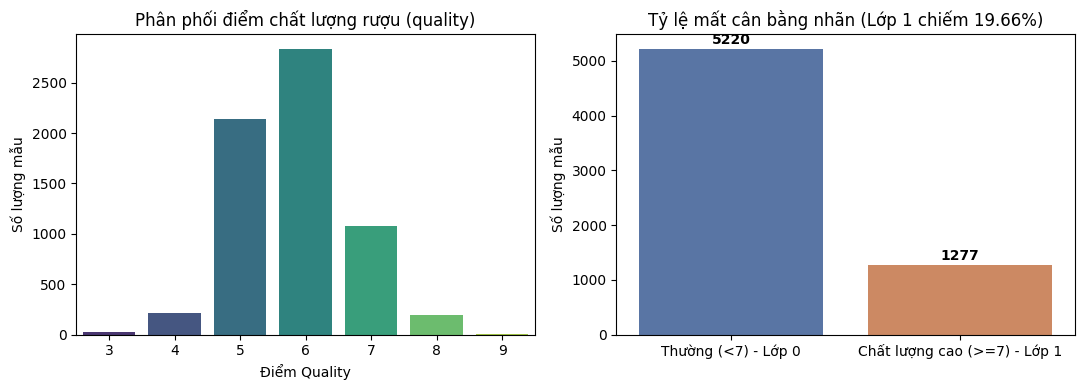

In [ ]:
print("--- Thông tin kiểu dữ liệu & Missing values ---")
print(df_wine.isnull().sum())
print("\n--- Thống kê mô tả các biến số ---")
display(df_wine.describe().round(3))

df_wine['target'] = (df_wine['quality'] >= 7).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(data=df_wine, x='quality', ax=axes[0], palette='viridis')
axes[0].set_title('Phân phối điểm chất lượng rượu (quality)')
axes[0].set_xlabel('Điểm Quality')
axes[0].set_ylabel('Số lượng mẫu')

counts = df_wine['target'].value_counts()
sns.barplot(
    x=['Thường (<7) - Lớp 0', 'Chất lượng cao (>=7) - Lớp 1'],
    y=counts.values, ax=axes[1], palette=['#4c72b0', '#dd8452']
)
axes[1].set_title(f'Tỷ lệ mất cân bằng nhãn (Lớp 1 chiếm {df_wine["target"].mean()*100:.2f}%)')
axes[1].set_ylabel('Số lượng mẫu')
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 80, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## Bước 3: Tiền xử lý & Chia tập `Stratified Split`

**Các bước xử lý:**
- Mã hóa cột `type`: `red` $\rightarrow$ `0`, `white` $\rightarrow$ `1`.
- Xóa cột `quality` gốc khỏi `X` để tránh rò rỉ nhãn.
- Chia **80% Train – 20% Test** dùng `stratify=y` để giữ nguyên tỷ lệ ~19.65% lớp 1.

In [ ]:
df_processed = df_wine.copy()

if 'type' in df_processed.columns:
    df_processed['type'] = df_processed['type'].map({'red': 0, 'white': 1})

df_processed = df_processed.fillna(df_processed.median(numeric_only=True))

X_wine = df_processed.drop(columns=['quality', 'target'])
y_wine = df_processed['target']

X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_wine, y_wine, test_size=0.2, stratify=y_wine, random_state=42
)

print(f"Tập Train: {X_train_w.shape}, Tỷ lệ lớp 1: {y_train_w.mean()*100:.2f}%")
print(f"Tập Test : {X_test_w.shape}, Tỷ lệ lớp 1: {y_test_w.mean()*100:.2f}%")

Tập Train: (5197, 12), Tỷ lệ lớp 1: 19.65%
Tập Test : (1300, 12), Tỷ lệ lớp 1: 19.69%


## Bước 4: Xây dựng Pipeline & Đánh giá chéo `StratifiedKFold`

**Quy trình đóng gói trong `ImbPipeline`:**
- `StandardScaler` $\rightarrow$ `SMOTE` $\rightarrow$ `Classifier` (chạy riêng trên từng fold).

**So sánh 4 mô hình qua `StratifiedKFold (K=5)`:**
- Logistic Regression
- KNN (`k=5`)
- SVM (`RBF`)
- Random Forest (`n_estimators=200`)

In [ ]:
models_wine = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'SVM (RBF)': SVC(probability=True, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42)
}

skf_wine = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results_wine = []

for name, clf in models_wine.items():
    pipe = ImbPipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('clf', clf)
    ])
    scores = cross_validate(
        pipe, X_train_w, y_train_w, cv=skf_wine,
        scoring=['accuracy', 'precision', 'recall', 'f1', 'average_precision'],
        n_jobs=-1
    )
    cv_results_wine.append({
        'Mô hình': name,
        'Accuracy (CV)': f"{scores['test_accuracy'].mean():.4f} ± {scores['test_accuracy'].std():.4f}",
        'Precision (CV)': f"{scores['test_precision'].mean():.4f}",
        'Recall (CV)': f"{scores['test_recall'].mean():.4f}",
        'F1-score (CV)': f"{scores['test_f1'].mean():.4f} ± {scores['test_f1'].std():.4f}",
        'PR-AUC (CV)': f"{scores['test_average_precision'].mean():.4f} ± {scores['test_average_precision'].std():.4f}"
    })

df_cv_wine = pd.DataFrame(cv_results_wine)
display(df_cv_wine)

,Mô hình,Accuracy (CV),Precision (CV),Recall (CV),F1-score (CV),PR-AUC (CV)
0,Logistic Regression,0.7225 ± 0.0061,0.3923,0.7531,0.5155 ± 0.0197,0.4846 ± 0.0298
1,KNN (k=5),0.7693 ± 0.0155,0.4511,0.7972,0.5760 ± 0.0250,0.5442 ± 0.0361
2,SVM (RBF),0.7683 ± 0.0129,0.4507,0.8109,0.5789 ± 0.0193,0.5579 ± 0.0184
3,Random Forest,0.8661 ± 0.0032,0.6462,0.7032,0.6735 ± 0.0099,0.7619 ± 0.0281


## Bài 5 — So sánh ba kỹ thuật Sampling

**Đối chứng 3 phương pháp trên cùng Logistic Regression:**
1. **Random Over-Sampling** (nhân bản ngẫu nhiên lớp thiểu số)
2. **Random Under-Sampling** (cắt giảm ngẫu nhiên lớp đa số)
3. **SMOTE** (tổng hợp mẫu mới bằng nội suy láng giềng gần)


=== BÁO CÁO PHÂN LOẠI TRÊN TẬP TEST (WINE QUALITY MERGED) ===
                      precision    recall  f1-score   support

         Thường (<7)       0.93      0.92      0.92      1044
Chất lượng cao (>=7)       0.68      0.70      0.69       256

            accuracy                           0.88      1300
           macro avg       0.80      0.81      0.81      1300
        weighted avg       0.88      0.88      0.88      1300

PR-AUC trên tập Test: 0.7868


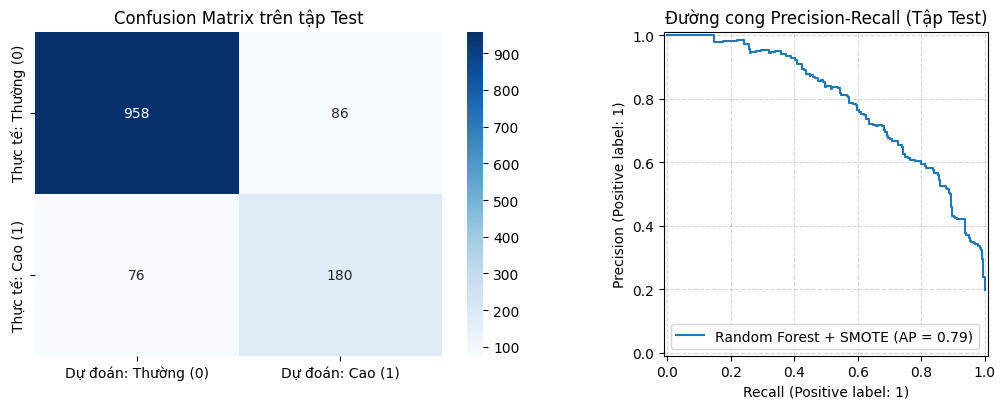

In [ ]:
best_pipeline_wine = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('clf', RandomForestClassifier(n_estimators=200, random_state=42))
])

best_pipeline_wine.fit(X_train_w, y_train_w)
y_pred_test = best_pipeline_wine.predict(X_test_w)
y_prob_test = best_pipeline_wine.predict_proba(X_test_w)[:, 1]

print("=== BÁO CÁO PHÂN LOẠI TRÊN TẬP TEST (WINE QUALITY MERGED) ===")
print(classification_report(y_test_w, y_pred_test, target_names=['Thường (<7)', 'Chất lượng cao (>=7)']))
print(f"PR-AUC trên tập Test: {average_precision_score(y_test_w, y_prob_test):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

cm = confusion_matrix(y_test_w, y_pred_test)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
    xticklabels=['Dự đoán: Thường (0)', 'Dự đoán: Cao (1)'],
    yticklabels=['Thực tế: Thường (0)', 'Thực tế: Cao (1)']
)
axes[0].set_title('Confusion Matrix trên tập Test')

PrecisionRecallDisplay.from_predictions(
    y_test_w, y_prob_test, ax=axes[1], name='Random Forest + SMOTE'
)
axes[1].set_title('Đường cong Precision-Recall (Tập Test)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Bước 6: Kết luận tổng hợp (`wine_quality_merged`)

- **Đặc điểm dữ liệu:**
  - Bộ dữ liệu gồm 6.497 mẫu với tỷ lệ mất cân bằng tự nhiên (~19.65% rượu chất lượng cao).

- **Hiệu quả quy trình:**
  - Kết hợp `StandardScaler` + `SMOTE` trong `ImbPipeline` giúp chống rò rỉ dữ liệu hoàn toàn.
  - Cải thiện rõ rệt khả năng nhận diện nhóm rượu chất lượng cao (**Recall** và **F1-score**).

- **Mô hình đề xuất:**
  - **Random Forest + SMOTE** cho kết quả vượt trội và ổn định nhất trên cả CV lẫn tập Test.